# XAI, metrics, checkpoints and a fresh 1,000-step 99.1M DDP run
Use the **same code-bundle dataset and training-data dataset** as before, with **GPU T4 x2**. This notebook adds external configs and audit helpers; it does not edit the original training source/config directories, preserving earlier checkpoint provenance.

Your existing 200-step run already contains residual/attention/router diagnostics. Logit Lens and SAE were off. This notebook can enable them, verify that they do not perturb training, verify exact checkpoint resume, and launch a fresh 1,000-step schedule on the full input corpus. The random Top-K SAE is a hook/sparsity plumbing test, not a trained interpretable SAE.


In [1]:
import os, sys, pathlib, shutil, zipfile, subprocess, importlib.util
from pathlib import Path
os.environ['CUBLAS_WORKSPACE_CONFIG']=':4096:8'
os.environ['PYTHONHASHSEED']='1234'
os.environ['OMP_NUM_THREADS']='1'
# Install only missing light dependencies. Keep Kaggle's working CUDA/PyTorch.
for module, package in [('yaml','PyYAML'),('tokenizers','tokenizers'),('numpy','numpy')]:
    if importlib.util.find_spec(module) is None:
        subprocess.run([sys.executable,'-m','pip','install',package],check=True)
import torch
print('Python:',sys.version,'\nTorch:',torch.__version__,'CUDA:',torch.version.cuda)
print('GPUs:',torch.cuda.device_count())
assert torch.cuda.device_count()==2, 'Select GPU T4 x2 in Kaggle notebook settings.'
for i in range(2):
    p=torch.cuda.get_device_properties(i)
    print(i,p.name,round(p.total_memory/2**30,2),'GiB')


Python: 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0] 
Torch: 2.11.0+cu128 CUDA: 12.8
GPUs: 2
0 Tesla T4 14.56 GiB
1 Tesla T4 14.56 GiB


In [2]:
ROOT=Path('/kaggle/working/team5-kaggle-100m-ddp')
if not (ROOT/'configs/kaggle_100m.yaml').exists():
    archives=list(Path('/kaggle/input').rglob('team5-kaggle-100m-ddp.zip'))
    if len(archives)==1:
        with zipfile.ZipFile(archives[0]) as z:
            base=Path('/kaggle/working').resolve()
            for item in z.infolist():
                if not (base/item.filename).resolve().is_relative_to(base):
                    raise ValueError('Unsafe archive path')
            z.extractall(base)
    else:
        configs=list(Path('/kaggle/input').rglob('kaggle_100m.yaml'))
        assert len(configs)==1, f'Attach the new bundle; found configs: {configs}'
        shutil.copytree(configs[0].parents[1],ROOT)
assert (ROOT/'harness/train_ddp.py').exists()
TOKENIZER=ROOT/'assets/tokenizer.json'
os.environ['BRAHMIC_TOKENIZER']=str(TOKENIZER)
os.chdir(ROOT)
print('Code:',ROOT,'\nTokenizer:',TOKENIZER)


Code: /kaggle/working/team5-kaggle-100m-ddp 
Tokenizer: /kaggle/working/team5-kaggle-100m-ddp/assets/tokenizer.json


In [3]:
# Automatic selection expects exactly one training and one validation source.
# If several exist, assign TRAIN and VAL explicitly using the printed file list.
def find_one(names):
    for name in names:
        found=list(Path('/kaggle/input').rglob(name))
        if len(found)==1:return found[0]
        if len(found)>1:raise ValueError(f'Choose one {name}: {found}')
    raise FileNotFoundError(f'Attach your pilot dataset; expected one of {names}')
TRAIN=find_one(['train.jsonl','train.jsonl.gz'])
VAL=find_one(['validation.jsonl','validation.jsonl.gz'])
print('Training:',TRAIN,'\nValidation:',VAL)
assert TRAIN != VAL


Training: /kaggle/input/datasets/udisinghania98/team5-moe-pilot-v0/team5_bundle/data/train.jsonl 
Validation: /kaggle/input/datasets/udisinghania98/team5-moe-pilot-v0/team5_bundle/data/validation.jsonl


In [4]:
def run_logged(command, log_path):
    log_path=Path(log_path);log_path.parent.mkdir(parents=True,exist_ok=True)
    print(' '.join(map(str,command)),flush=True)
    with log_path.open('w') as log:
        process=subprocess.Popen(list(map(str,command)),cwd=ROOT,env=os.environ.copy(),
                                 stdout=subprocess.PIPE,stderr=subprocess.STDOUT,text=True,bufsize=1)
        try:
            for line in process.stdout:
                print(line,end='',flush=True);log.write(line);log.flush()
            result=process.wait()
        except BaseException:
            process.terminate();process.wait();raise
    if result:raise RuntimeError(f'Exit {result}; full error log: {log_path}')
    return log_path


**Additive setup.** New files go to `/kaggle/working/team5_xai_1000_tools`, outside the training tree. The three configs are written before any run. Do not edit the original `harness/` or `configs/` while resuming earlier checkpoints.


In [5]:
EXTRAS=Path('/kaggle/working/team5_xai_1000_tools')
EXTRAS.mkdir(exist_ok=True)
(EXTRAS/'audit_ddp.py').write_text('"""Audit saved DDP records and optional local checkpoint. Does not train."""\nimport argparse,hashlib,json,math,pathlib,statistics\n\n\ndef finite(value):\n    if isinstance(value,dict):return all(finite(v) for v in value.values())\n    if isinstance(value,list):return all(finite(v) for v in value)\n    return not isinstance(value,float) or math.isfinite(value)\n\n\ndef audit(root,checkpoint=False):\n    root=pathlib.Path(root);manifest=json.loads((root/\'manifest.json\').read_text())\n    summary=json.loads((root/\'summary.json\').read_text())\n    rows=[json.loads(line) for line in (root/\'metrics.jsonl\').read_text().splitlines()]\n    c=manifest[\'config\'];world=manifest[\'world_size\'];expected=c[\'data_curriculum\'][\'global_tokens_per_step\'];k=c[\'moe\'][\'num_experts_per_tok\']\n    assert rows and len(rows)==summary[\'completed_steps\']\n    assert [r[\'step\'] for r in rows]==list(range(1,len(rows)+1))\n    assert finite(rows) and finite(summary),\'Nonfinite record\'\n    assert summary[\'nan_count\']==0 and summary[\'rank_models_identical\']\n    assert not (root/\'alarms.jsonl\').read_text().strip(),\'Recorded alarms\'\n    keys=[\'explain/residual_cosine\',\'explain/residual_l2\',\'explain/attention_entropy_per_head\',\'explain/logit_lens_kl\']\n    coverage={key:[] for key in keys};sae_steps=[];global_entropies=[];global_unused=[];max_global_overloads=[]\n    for row in rows:\n        assert row[\'train/valid_tokens\']==expected\n        assert math.isclose(row[\'train/perplexity\'],math.exp(row[\'loss/ce\']),rel_tol=1e-12)\n        assert math.isclose(row[\'train/bpb\'],row[\'loss/ce\']*expected/(math.log(2)*row[\'train/raw_utf8_bytes\']),rel_tol=1e-10)\n        if \'val/ce_loss\' in row:\n            assert math.isclose(row[\'val/perplexity\'],math.exp(row[\'val/ce_loss\']),rel_tol=1e-12)\n            assert row[\'val/bpb\']>0\n        ranks=row[\'ranks\'];assert len(ranks)==world\n        for i in range(world):\n            for j in range(i):assert not set(ranks[i][\'window_indices\'])&set(ranks[j][\'window_indices\'])\n        for key in keys:\n            if any(key in layer for rank in ranks for layer in rank[\'layers\']):coverage[key].append(row[\'step\'])\n        if any(layer.get(\'explain/sae\') for rank in ranks for layer in rank[\'layers\']):sae_steps.append(row[\'step\'])\n        for layer_index in range(c[\'model\'][\'num_layers\']):\n            counts=[0.]*c[\'moe\'][\'num_experts\']\n            for rank in ranks:\n                layer=rank[\'layers\'][layer_index]\n                if \'explain/residual_cosine\' in layer:assert -1.000001<=layer[\'explain/residual_cosine\']<=1.000001\n                if \'explain/attention_entropy_per_head\' in layer:\n                    assert len(layer[\'explain/attention_entropy_per_head\'])==c[\'attention\'][\'query_heads\']\n                    assert all(-1e-6<=v<=math.log(c[\'training\'][\'sequence_length\'])+1e-5 for v in layer[\'explain/attention_entropy_per_head\'])\n                for probe in layer.get(\'explain/sae\',[]):\n                    assert 0<=probe[\'explain/sae_feature_l0\']<=c[\'explainability\'][\'sae_probe\'][\'top_k\']\n                    assert probe[\'explain/sae_reconstruction_mse\']>=0\n                    assert 0<=probe[\'explain/sae_dead_feature_fraction\']<=1\n                if \'moe/expert_counts\' not in layer:continue\n                assert layer[\'moe/dropped_token_ratio\']==0,\'Dropped tokens in dropless pilot\'\n                assert math.isclose(sum(layer[\'moe/expert_counts\']),rank[\'local_tokens\']*k)\n                counts=[a+b for a,b in zip(counts,layer[\'moe/expert_counts\'])]\n            total=sum(counts)\n            if total:\n                p=[v/total for v in counts]\n                global_entropies.append(-sum(v*math.log(v) for v in p if v)/math.log(len(p)))\n                global_unused.append(sum(v==0 for v in counts))\n                max_global_overloads.append(max(counts)/(total/len(counts))-1)\n    report=dict(status=\'PASS\',steps=len(rows),parameters=manifest[\'parameters\'],world_size=world,\n                metrics_finite=True,ppl_formula_verified=True,train_bpb_formula_verified=True,\n                validation_bpb_note=\'Val NLL/bytes are not logged per event; final values are in summary, so raw-byte formula cannot be independently reconstructed for every val event\',\n                disjoint_rank_windows=True,global_tokens_per_step=expected,nan_count=0,\n                rank_model_states_identical=summary[\'rank_models_identical\'],xai_step_coverage=coverage,sae_step_coverage=sae_steps,\n                global_expert_entropy_min=min(global_entropies),global_expert_entropy_mean=statistics.mean(global_entropies),\n                globally_unused_experts_in_one_layer_update_max=max(global_unused),\n                global_max_load_violation_max=max(max_global_overloads),\n                peak_pytorch_allocated_gib=max(r[\'memory/max_allocated_bytes_per_rank\'] for r in rows)/2**30,\n                training_documents=manifest[\'train_documents\'],validation_documents=manifest[\'validation_documents\'],\n                final_validation=summary[\'final_validation\'],\n                sae_note=\'Random Top-K probe only checks hook/reconstruction/sparsity plumbing; no trained SAE features or calibrated collapse diagnosis\')\n    v=summary[\'final_validation\']\n    assert math.isclose(v[\'bpb\'],v[\'ce\']*v[\'tokens\']/(math.log(2)*v[\'bytes\']),rel_tol=1e-10)\n    report[\'final_validation_bpb_formula_verified\']=True\n    if checkpoint:\n        import torch\n        path=root/\'checkpoint.pt\';state=torch.load(path,map_location=\'cpu\',weights_only=True,mmap=True)\n        for key in [\'model\',\'optimizers\',\'scheduler\',\'curriculum\',\'rank_states\',\'records\',\'identity\',\'active_stage\']:assert key in state,key\n        assert state[\'step\']==summary[\'completed_steps\']==state[\'scheduler\'][\'step\']==state[\'curriculum\'][\'step\']\n        assert state[\'curriculum\'][\'tokens_seen\']==len(rows)*expected\n        assert len(state[\'rank_states\'])==world\n        assert len(list(root.glob(\'checkpoint_step_*.pt\')))<=c[\'checkpointing\'][\'keep_last_n\']\n        for local in state[\'rank_states\']:\n            assert all(key in local[\'sampler\'] for key in [\'generator\',\'orders\',\'positions\'])\n            assert all(key in local[\'rng\'] for key in [\'python\',\'numpy\',\'cpu\',\'cuda\'])\n        assert len(state[\'optimizers\'])==len(manifest[\'optimizer_groups\'][\'optimizer_order\'])\n        digest=hashlib.sha256()\n        for name,value in sorted(state[\'model\'].items()):digest.update(name.encode());digest.update(value.contiguous().numpy().tobytes())\n        assert digest.hexdigest()==summary[\'final_model_sha256\'],\'Checkpoint weights differ from final summary\'\n        report[\'checkpoint\']=dict(status=\'PASS\',step=state[\'step\'],bytes=path.stat().st_size,\n             complete_optimizer_scheduler_curriculum_sampler_rng=True,model_hash_matches_final_summary=True,\n             numbered_checkpoints=len(list(root.glob(\'checkpoint_step_*.pt\'))),\n             retention_limit=c[\'checkpointing\'][\'keep_last_n\'])\n    (root/\'audit_report.json\').write_text(json.dumps(report,indent=2))\n    print(json.dumps(report,indent=2));return report\n\n\ndef compare(a,b):\n    a,b=pathlib.Path(a),pathlib.Path(b)\n    for name in [\'loss.txt\',\'total_loss.txt\']:assert (a/name).read_bytes()==(b/name).read_bytes(),name+\' differs\'\n    sa,sb=[json.loads((p/\'summary.json\').read_text()) for p in [a,b]]\n    assert sa[\'final_model_sha256\']==sb[\'final_model_sha256\'],\'Final model states differ\'\n    records=[[json.loads(l) for l in (p/\'metrics.jsonl\').read_text().splitlines()] for p in [a,b]]\n    def batches(rows):return [[(r[\'rank\'],r[\'batch_sha256\'],r[\'window_indices\']) for r in row[\'ranks\']] for row in rows]\n    assert batches(records[0])==batches(records[1]),\'Data batches differ\'\n    print(\'PASS: CE + total-loss EMPTY DIFF; final model hashes and rank batches identical\')\n\n\nif __name__==\'__main__\':\n    p=argparse.ArgumentParser();p.add_argument(\'run\');p.add_argument(\'--checkpoint\',action=\'store_true\');p.add_argument(\'--compare\')\n    a=p.parse_args()\n    if a.compare:compare(a.run,a.compare)\n    else:audit(a.run,a.checkpoint)\n',encoding='utf8')
(EXTRAS/'make_configs.py').write_text('"""Write experiment overrides OUTSIDE the immutable training source tree."""\nimport argparse,copy,pathlib,yaml\n\n\ndef write(path,c):\n    text=yaml.safe_dump(c,sort_keys=False,allow_unicode=True)\n    text=\'\\n\'.join(line+\'  # source: G5 explicit XAI/1000-step verification experiment, 26 Oct; not TSAI production approval\' for line in text.splitlines())+\'\\n\'\n    path.write_text(text,encoding=\'utf8\')\n\n\ndef make(root,out):\n    root,out=pathlib.Path(root),pathlib.Path(out);out.mkdir(parents=True,exist_ok=True)\n    if out.resolve().is_relative_to(root.resolve()):raise ValueError(\'Keep new configs outside training ROOT to preserve old checkpoint source hashes\')\n    base=yaml.safe_load((root/\'configs/kaggle_100m.yaml\').read_text())\n    on=copy.deepcopy(base);on[\'training\'].update(steps=1000,warmup_steps=100)\n    on.setdefault(\'data\',{}).update(mode=\'deterministic_slice\',slice_documents=64)\n    on[\'evaluation\'].update(eval_every_steps=2,eval_batches=2)\n    on[\'explainability\'].update(enabled=True,enable_logit_lens=True,tap_every_steps=2,logit_lens_every_steps=2)\n    on[\'explainability\'][\'sae_probe\']=dict(enabled=True,kind=\'random_topk_reference\')\n    on[\'checkpointing\'].update(save_every_steps=2,keep_last_n=2)\n    off=copy.deepcopy(on);off[\'explainability\'][\'enabled\']=False\n    main=copy.deepcopy(on);main[\'data\'].update(mode=\'full\')\n    main[\'evaluation\'].update(eval_every_steps=50,eval_batches=32)\n    main[\'explainability\'].update(tap_every_steps=50,logit_lens_every_steps=200)\n    main[\'checkpointing\'].update(save_every_steps=100,keep_last_n=2)\n    main[\'data_curriculum\'][\'transition_ramp_steps\']=20\n    for name,c in [(\'xai_on.yaml\',on),(\'xai_off.yaml\',off),(\'xai_1000_full_data.yaml\',main)]:write(out/name,c)\n    print(\'Wrote configs:\',out)\n\nif __name__==\'__main__\':\n    p=argparse.ArgumentParser();p.add_argument(\'--root\',required=True);p.add_argument(\'--out\',required=True);a=p.parse_args();make(a.root,a.out)\n',encoding='utf8')
CONF=EXTRAS/'configs'
run_logged([sys.executable,EXTRAS/'make_configs.py','--root',ROOT,'--out',CONF],EXTRAS/'config_generation.log')
for name in ['xai_on.yaml','xai_off.yaml','xai_1000_full_data.yaml']:
    run_logged([sys.executable,'harness/check_config.py','--override',CONF/name],EXTRAS/(name+'.check.log'))
RUNS=Path('/kaggle/working/runs')
BASE_COMMAND=[sys.executable,'-m','torch.distributed.run','--standalone','--nproc_per_node=2',
              'harness/train_ddp.py','--device','cuda','--seed','1234','--tokenizer',str(TOKENIZER),
              '--data-path',str(TRAIN),'--validation-data-path',str(VAL)]
def command(config,name,stop=None,resume=None):
    result=BASE_COMMAND+['--override',str(CONF/config),'--out',str(RUNS/name)]
    if stop is not None:result+=['--stop-after',str(stop)]
    if resume is not None:result+=['--resume',str(resume)]
    return result


/usr/bin/python3 /kaggle/working/team5_xai_1000_tools/make_configs.py --root /kaggle/working/team5-kaggle-100m-ddp --out /kaggle/working/team5_xai_1000_tools/configs
Wrote configs: /kaggle/working/team5_xai_1000_tools/configs
/usr/bin/python3 harness/check_config.py --override /kaggle/working/team5_xai_1000_tools/configs/xai_on.yaml
0 errors
/usr/bin/python3 harness/check_config.py --override /kaggle/working/team5_xai_1000_tools/configs/xai_off.yaml
0 errors
/usr/bin/python3 harness/check_config.py --override /kaggle/working/team5_xai_1000_tools/configs/xai_1000_full_data.yaml
0 errors


**Audit the previous run, if still present.** This reads saved records, checks formula consistency and rank data shards, and verifies that the checkpoint contains both optimizers, scheduler, curriculum, per-rank sampler/RNG state, and weights matching the final model hash. The downloaded result ZIP excludes checkpoints; this cell needs the actual local `checkpoint.pt` in Kaggle.


In [6]:
old=RUNS/'pilot_200'
if (old/'summary.json').exists():
    args=[sys.executable,EXTRAS/'audit_ddp.py',old]
    if (old/'checkpoint.pt').exists():args+=['--checkpoint']
    run_logged(args,EXTRAS/'previous_200_audit.log')
else:
    print('Previous working-directory results are absent. This does not block fresh tests.')


Previous working-directory results are absent. This does not block fresh tests.


**Four short diagnostic launches.** Set RUN_DIAGNOSTICS=True. They use the real 99.1M model, two GPUs, and the same bounded data slice. The XAI-on config enables attention/residual telemetry, Logit Lens KL and the random Top-K probe at steps 1/2/4. Expected: on/off losses and final weights match; 2+2 resumed updates match four uninterrupted updates. Checkpointing is inspected with a safe CPU/memory-mapped load. No old checkpoint or old run folder is overwritten.


In [7]:
RUN_DIAGNOSTICS=True
if RUN_DIAGNOSTICS:
    jobs=[('xai_on.yaml','diag_xai_on',4,None),
          ('xai_off.yaml','diag_xai_off',4,None),
          ('xai_on.yaml','diag_paused',2,None),
          ('xai_on.yaml','diag_resumed',4,RUNS/'diag_paused/checkpoint.pt')]
    for config,name,stop,resume in jobs:
        run_logged(command(config,name,stop,resume),EXTRAS/(name+'.log'))
    for other in ['diag_xai_off','diag_resumed']:
        run_logged([sys.executable,EXTRAS/'audit_ddp.py',RUNS/'diag_xai_on','--compare',RUNS/other],
                   EXTRAS/(other+'_comparison.log'))
    run_logged([sys.executable,EXTRAS/'audit_ddp.py',RUNS/'diag_xai_on','--checkpoint'],EXTRAS/'diag_audit.log')
else:
    print('Diagnostics not started; set RUN_DIAGNOSTICS=True when ready.')


/usr/bin/python3 -m torch.distributed.run --standalone --nproc_per_node=2 harness/train_ddp.py --device cuda --seed 1234 --tokenizer /kaggle/working/team5-kaggle-100m-ddp/assets/tokenizer.json --data-path /kaggle/input/datasets/udisinghania98/team5-moe-pilot-v0/team5_bundle/data/train.jsonl --validation-data-path /kaggle/input/datasets/udisinghania98/team5-moe-pilot-v0/team5_bundle/data/validation.jsonl --override /kaggle/working/team5_xai_1000_tools/configs/xai_on.yaml --out /kaggle/working/runs/diag_xai_on --stop-after 4
Rank 0: initializing nccl rendezvous
Rank 1: initializing nccl rendezvous
/usr/local/lib/python3.13/dist-packages/torch/distributed/c10d_logger.py:83: UserWarning: barrier(): using the device under current context. You can specify `device_id` in `init_process_group` to mute this warning.
  return func(*args, **kwargs)
[rank0]:[W1026 14:03:38.127658929 ProcessGroupNCCL.cpp:5188] Guessing device ID based on global rank. This can cause a hang if rank to GPU mapping is h

**Fresh 1,000-step experiment.** Set RUN_1000=True after the diagnostics pass. This starts from seed 1234, not from the 200-step checkpoint. It uses all documents in the supplied files (the scored budget is still 512,000 tokens total), 100 warmup updates, fixed context 128, native XAI taps every 50 steps, Logit Lens every 200 steps plus step 1, and the random SAE probe. Evaluation samples up to 64 fixed validation windows every 50 steps; it is not full or domain-balanced benchmark evaluation. Checkpoints save every 100 steps, keeping two numbered files plus the latest alias.

Based on your previous run, baseline training scales to roughly 22 minutes; allow additional startup, evaluation, probe and checkpoint overhead. Measure the actual time. Dataset parsing/cache construction happens separately on both ranks and can take time before the first step print.


In [8]:
RUN_1000=True
if RUN_1000:
    run_logged(command('xai_1000_full_data.yaml','xai_1000'),EXTRAS/'xai_1000_console.log')
    run_logged([sys.executable,EXTRAS/'audit_ddp.py',RUNS/'xai_1000','--checkpoint'],EXTRAS/'xai_1000_audit.log')
else:
    print('1,000-step run not started; set RUN_1000=True after diagnostic checks.')


/usr/bin/python3 -m torch.distributed.run --standalone --nproc_per_node=2 harness/train_ddp.py --device cuda --seed 1234 --tokenizer /kaggle/working/team5-kaggle-100m-ddp/assets/tokenizer.json --data-path /kaggle/input/datasets/udisinghania98/team5-moe-pilot-v0/team5_bundle/data/train.jsonl --validation-data-path /kaggle/input/datasets/udisinghania98/team5-moe-pilot-v0/team5_bundle/data/validation.jsonl --override /kaggle/working/team5_xai_1000_tools/configs/xai_1000_full_data.yaml --out /kaggle/working/runs/xai_1000
Rank 1: initializing nccl rendezvous
Rank 0: initializing nccl rendezvous
/usr/local/lib/python3.13/dist-packages/torch/distributed/c10d_logger.py:83: UserWarning: barrier(): using the device under current context. You can specify `device_id` in `init_process_group` to mute this warning.
  return func(*args, **kwargs)
[rank0]:[W1026 14:05:55.742152369 ProcessGroupNCCL.cpp:5188] Guessing device ID based on global rank. This can cause a hang if rank to GPU mapping is heterog

If a session stops, resume the same schedule/config/data/code/world size into a NEW output directory. Use the checkpoint's actual path; do not alter the config to change training.steps. Exact reproducibility across a changed Kaggle software/hardware environment is not promised.


In [ ]:
RUN_RESUME_1000=True
if RUN_RESUME_1000:
    checkpoint=RUNS/'xai_1000/checkpoint.pt'
    run_logged(command('xai_1000_full_data.yaml','xai_1000_resumed',resume=checkpoint),EXTRAS/'xai_1000_resumed.log')
    run_logged([sys.executable,EXTRAS/'audit_ddp.py',RUNS/'xai_1000_resumed','--checkpoint'],EXTRAS/'xai_1000_resumed_audit.log')


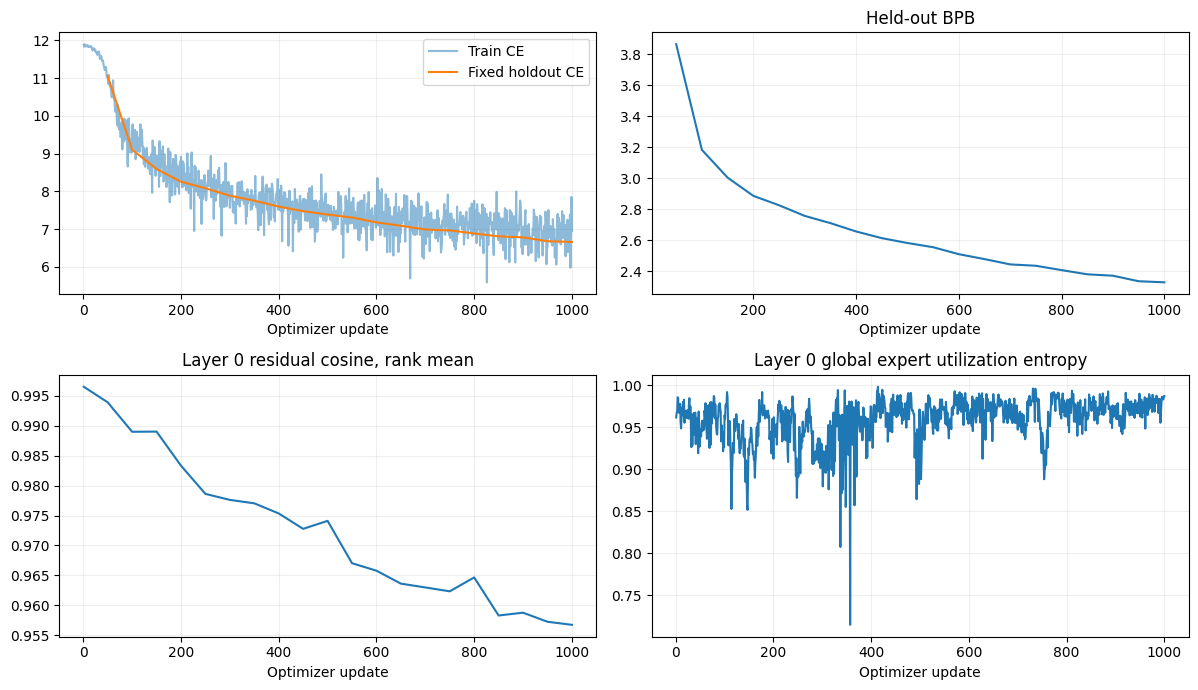

In [9]:
# Plot saved records only; this cell starts no training.
import json, math
import matplotlib.pyplot as plt
TARGET=RUNS/'xai_1000'
if (TARGET/'metrics.jsonl').exists():
    rows=[json.loads(line) for line in (TARGET/'metrics.jsonl').read_text().splitlines()]
    fig,axes=plt.subplots(2,2,figsize=(12,7))
    axes[0,0].plot([r['step'] for r in rows],[r['loss/ce'] for r in rows],alpha=.5,label='Train CE')
    val=[r for r in rows if 'val/ce_loss' in r]
    axes[0,0].plot([r['step'] for r in val],[r['val/ce_loss'] for r in val],label='Fixed holdout CE');axes[0,0].legend()
    axes[0,1].plot([r['step'] for r in val],[r['val/bpb'] for r in val]);axes[0,1].set_title('Held-out BPB')
    taps=[r for r in rows if 'explain/residual_cosine' in r['ranks'][0]['layers'][0]]
    axes[1,0].plot([r['step'] for r in taps],[sum(rank['layers'][0]['explain/residual_cosine'] for rank in r['ranks'])/len(r['ranks']) for r in taps])
    axes[1,0].set_title('Layer 0 residual cosine, rank mean')
    def global_entropy(row):
        counts=[sum(rank['layers'][0]['moe/expert_counts'][i] for rank in row['ranks']) for i in range(8)]
        total=sum(counts);p=[n/total for n in counts]
        return -sum(v*math.log(v) for v in p if v)/math.log(len(p))
    axes[1,1].plot([r['step'] for r in rows],[global_entropy(r) for r in rows]);axes[1,1].set_title('Layer 0 global expert utilization entropy')
    for ax in axes.flat:ax.set_xlabel('Optimizer update');ax.grid(alpha=.2)
    fig.tight_layout();fig.savefig(EXTRAS/'xai_1000_curves.png',dpi=150);plt.show()
else:
    print('No xai_1000 records yet.')


In [10]:
# Export diagnostics without GB-scale checkpoints or token caches.
report=Path('/kaggle/working/team5_xai_1000_results.zip')
with zipfile.ZipFile(report,'w',zipfile.ZIP_DEFLATED) as z:
    for name in ['diag_xai_on','diag_xai_off','diag_paused','diag_resumed','xai_1000','xai_1000_resumed']:
        run=RUNS/name
        if run.exists():
            for file in run.iterdir():
                if file.is_file() and file.suffix in ['.json','.jsonl','.txt']:
                    z.write(file,file.relative_to('/kaggle/working'))
    for file in EXTRAS.rglob('*'):
        if file.is_file() and file.suffix in ['.json','.yaml','.log','.png']:
            z.write(file,file.relative_to('/kaggle/working'))
print('Download:',report)
print('Download the desired checkpoint.pt separately to preserve training state.')


Download: /kaggle/working/team5_xai_1000_results.zip
Download the desired checkpoint.pt separately to preserve training state.


In [11]:
from pathlib import Path
from IPython.display import FileLink, display

checkpoint = Path("/kaggle/working/runs/xai_1000/checkpoint.pt")
assert checkpoint.exists(), f"Checkpoint not found: {checkpoint}"

print(f"Size: {checkpoint.stat().st_size / 2**30:.2f} GiB")
display(FileLink(str(checkpoint)))

Size: 0.95 GiB


/kaggle/working/runs/xai_1000/checkpoint.pt